# 03 · Fig. 1: annual maximum, the two lows and energy

**Purpose.** Draw Fig. 1 and show the numbers behind it.

**Paper section served.** I Introduction.

**Inputs**

- `data/interim/network_30min.parquet` from notebook 01.

**Paper artifacts**

- `outputs/figures/fig1.png` (600 dpi) and `fig1.pdf`: Fig. 1.
- `outputs/tables/fig1_data.csv`: the values plotted.

**Supporting checks.** None.

**Main process**

1. Set up.
2. Summarise each year.
3. Draw and save Fig. 1.
4. Result.

## 1. Set up

`set_style` applies the shared figure style: one IEEE column wide, 8 pt serif text, no title inside the figure.

In [1]:
import pandas as pd

from pynmdf import plots, targets
from pynmdf.config import load_config

cfg = load_config()
interim, figures, tables = (cfg["dirs"][key] for key in ("interim", "figures", "tables"))
plots.set_style()

pd.set_option("display.width", 220, "display.float_format", "{:,.1f}".format)
total = pd.read_parquet(interim / "network_30min.parquet")["total_mw"]

## 2. Each year in four numbers

The maximum is the highest valid half hour of the calendar year. The minimum is split in two: the **overnight low** is the lowest half hour between 00:00 and 06:00, and the **daytime low** the lowest between 09:00 and 17:00. The year's minimum is the lower of the two. Energy allows for gaps: the mean of the valid half hours times the hours in the year.

In [2]:
lows = targets.annual_window_lows(total, cfg["targets"]["troughs"])
annual = targets.annual_summary(total).join(lows)
plotted = annual[["max_mw", "overnight_low_mw", "daytime_low_mw", "energy_gwh"]]
plotted.to_csv(tables / "fig1_data.csv")
plotted.T

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
max_mw,"4,632.8","4,717.1","5,268.9","4,675.8","5,146.2","5,065.7","4,459.0","4,226.3","4,756.6","4,679.1","4,606.5"
overnight_low_mw,"1,368.1","1,432.6","1,474.3","1,495.1","1,473.0","1,429.5","1,387.6","1,428.3","1,393.2","1,419.6","1,434.9"
daytime_low_mw,"1,832.6","1,891.4","1,888.2","1,901.7","1,759.2","1,671.0","1,357.4","1,457.9","1,080.0","1,019.2",880.1
energy_gwh,"21,444.1","22,012.8","22,386.1","22,291.2","21,931.3","20,926.9","19,805.0","20,174.5","19,286.6","19,685.5","19,872.4"


## 3. Fig. 1

Maximum demand, the overnight low and the daytime low are lines on the left axis (MW); annual energy is bars on the right axis (GWh). The two scales are aligned so that 1,000 MW sits level with 10,000 GWh, which makes the gridlines serve both axes.

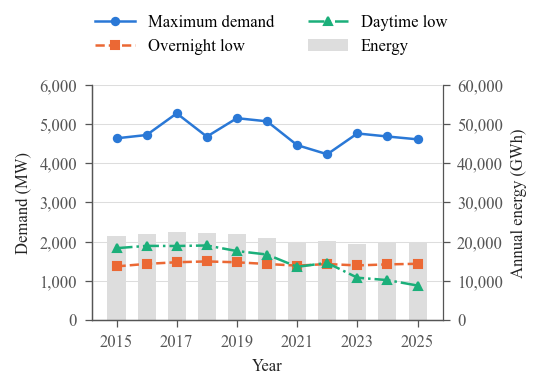

In [3]:
figure = plots.fig1_annual_demand(annual)
plots.save_figure(figure, figures, "fig1")

## 4. Result

Change from the first year of the window to the last for each series in Fig. 1, and the years in which the daytime low sits below the overnight low.

In [4]:
ends = plotted.loc[[plotted.index[0], plotted.index[-1]]].T
ends["change_pct"] = 100 * (ends.iloc[:, 1] / ends.iloc[:, 0] - 1)

daytime_lower = annual.index[annual["daytime_low_mw"] < annual["overnight_low_mw"]]
print("Years in which the daytime low is below the overnight low:", daytime_lower.tolist())
ends

Years in which the daytime low is below the overnight low: [2021, 2023, 2024, 2025]


year,2015,2025,change_pct
max_mw,"4,632.8","4,606.5",-0.6
overnight_low_mw,"1,368.1","1,434.9",4.9
daytime_low_mw,"1,832.6",880.1,-52.0
energy_gwh,"21,444.1","19,872.4",-7.3
